| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_5_Neural_ODEs.ipynb) | [⏩](../16_UNCERTAINTY_QUANTIFICATION/16_1_UNCERTAINTY_QUANTIFICATION.ipynb) |

# 15.6 Differentiable Physics: aprender parámetros a través de una simulación

En física diferenciable, un simulador forma parte de un programa cuyo resultado puede derivarse respecto a parámetros, condiciones iniciales o controles. Usaremos la trayectoria de un oscilador para identificar rigidez y amortiguamiento; después derivaremos una solución de Poisson mediante un sistema lineal.

**Objetivos:** seguir la cadena parámetro → simulación → observación → pérdida; verificar gradientes; distinguir derivadas explícitas e implícitas; examinar error de discretización e identificabilidad. **Prerrequisitos:** 5.1 ODE, 7.4 RK4, 10 optimización, 14 inversos y 15.5 Neural ODEs. **Librerías:** NumPy, SciPy, Matplotlib y PyTorch. CPU, datos sintéticos y ejecución secuencial.

## 1. Un simulador como función de parámetros

Un problema directo produce $u=S(\theta,u_0)$. Un operador de observación $H$ convierte el estado en magnitudes medibles. Para observaciones $y$, construimos

$$\mathcal L(\theta)=\|H(S(\theta,u_0))-y\|^2.$$

La regla de la cadena relaciona derivadas de pérdida, observación y simulación. Podemos optimizar parámetros con gradientes aunque no exista una fórmula explícita de la trayectoria.

El simulador sigue siendo una aproximación física y numérica. Un gradiente correcto del código no garantiza un modelo correcto del experimento. Tenemos que verificar tanto el programa como su relación con los datos.

En una Neural ODE suele aprenderse el campo. Aquí mantendremos la ecuación del campo y aprenderemos dos coeficientes físicos. Ambas son formas de combinar dinámica y aprendizaje, con grados de libertad distintos.

## 2. Oscilador amortiguado y observaciones parciales

Con masa conocida $m=1$, el sistema es

$$x'=v,\qquad v'=-kx-cv,\qquad x(0)=1,\quad v(0)=0.$$

La rigidez $k>0$ controla la frecuencia y $c>0$ el amortiguamiento. La energía $E=(v^2+kx^2)/2$ cumple $E'=-cv^2\leq0$. El comportamiento observado combina fase y decaimiento; ambos ayudan a distinguir parámetros.

Si también aprendiéramos una masa desconocida, observaríamos principalmente los cocientes $k/m$ y $c/m$. Sin información adicional, no podríamos identificar independientemente los tres valores. Fijar la masa es una elección de identificabilidad, no un detalle de implementación.

Generaremos mediciones únicamente de posición cada $0.15$ unidades de tiempo y añadiremos ruido gaussiano de desviación $0.002$. Las velocidades permanecen ocultas. El generador usa `solve_ivp` con tolerancias estrictas, distinto del solver diferenciable de entrenamiento.

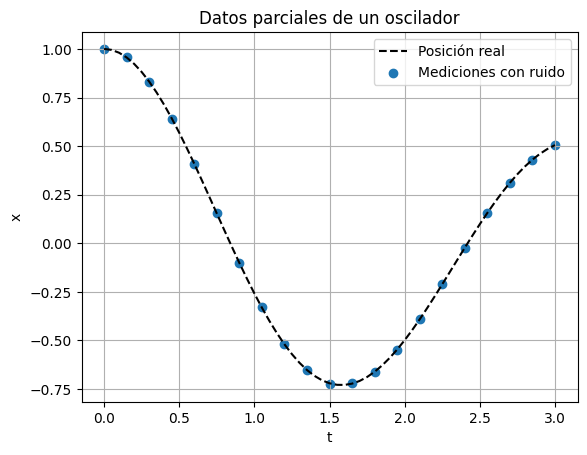

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import torch
from torch import nn
torch.manual_seed(156)
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(156)
k_real, c_real = 4.0, 0.4
tf = 3.0
n_pasos = 60
h = tf/n_pasos
ts = np.linspace(0, tf, n_pasos+1)
z0 = torch.tensor([1.0, 0.0])
sol = solve_ivp(lambda t,z: [z[1], -k_real*z[0]-c_real*z[1]],
                (0,tf), [1.0,0.0], t_eval=ts, rtol=1e-11, atol=1e-13)
assert sol.success
indices = np.arange(0,n_pasos+1,3)
y_obs_np = sol.y[0,indices] + rng.normal(0,0.002,len(indices))
y_obs = torch.tensor(y_obs_np)
plt.plot(ts,sol.y[0], 'k--',label='Posición real')
plt.scatter(ts[indices],y_obs_np,label='Mediciones con ruido')
plt.xlabel('t'); plt.ylabel('x'); plt.title('Datos parciales de un oscilador')
plt.legend(); plt.grid(); plt.show()

## 3. Implementar RK4 conservando el grafo

Cada paso de RK4 combina cuatro evaluaciones del campo. Mantener tensores de PyTorch permite que autograd siga la dependencia de todos los estados respecto a $k$ y $c$.

Evita convertir a `float`, llamar a NumPy o usar `detach()` dentro del integrador. Un `float` extraído de un parámetro rompe su conexión con la pérdida. Para registrar valores después de calcular la pérdida sí podemos usar `.item()`.

Parametrizamos $k=\operatorname{softplus}(\eta_k)$ y $c=\operatorname{softplus}(\eta_c)$ para asegurar positividad durante el ajuste. Estas transformaciones también afectan los gradientes, por lo que elegiremos valores iniciales con una escala razonable.

In [2]:
def campo(z, k, c):
    return torch.stack([z[1], -k*z[0]-c*z[1]])

def simular(k, c, n=60, tiempo_final=3.0):
    paso = tiempo_final/n
    z = z0
    estados = [z]
    for _ in range(n):
        f1 = campo(z,k,c)
        f2 = campo(z+paso*f1/2,k,c)
        f3 = campo(z+paso*f2/2,k,c)
        f4 = campo(z+paso*f3,k,c)
        z = z+paso*(f1+2*f2+2*f3+f4)/6
        estados.append(z)
    return torch.stack(estados)

def inversa_softplus(x):
    return np.log(np.expm1(x))
eta = nn.Parameter(torch.tensor([inversa_softplus(2.0), inversa_softplus(0.8)]))
def parametros():
    positivos = torch.nn.functional.softplus(eta)
    return positivos[0], positivos[1]

k0,c0 = parametros()
inicial = simular(k0,c0)
print('Forma [tiempo, estado]:',tuple(inicial.shape))
print('Parámetros iniciales:', k0.item(), c0.item())

Forma [tiempo, estado]: (61, 2)
Parámetros iniciales: 2.0 0.8


## 4. Comprobar una derivada antes de optimizar

Construimos la pérdida de posiciones $\mathcal L=\frac1N\sum_i[x_\theta(t_i)-y_i]^2$. Compararemos $\partial\mathcal L/\partial\eta_k$ de autograd con una diferencia central.

Estamos comprobando el programa discreto con el mismo solver y las mismas observaciones. Usar un solver distinto en la diferencia finita mezclaría error de derivación y de simulación. La prueba se hace antes de alcanzar un mínimo, donde los gradientes podrían ser casi cero y la comparación poco informativa.

In [3]:
def perdida():
    k,c = parametros()
    return ((simular(k,c)[indices,0]-y_obs)**2).mean()

loss0 = perdida()
g_aut = torch.autograd.grad(loss0, eta)[0][0].item()
valor = eta[0].item(); eps = 1e-5
with torch.no_grad():
    eta[0]=valor+eps; lmas=perdida().item()
    eta[0]=valor-eps; lmenos=perdida().item()
    eta[0]=valor
g_fd = (lmas-lmenos)/(2*eps)
print('dL/d eta_k: autograd=',g_aut,'| diferencia central=',g_fd)
assert np.isclose(g_aut,g_fd,rtol=1e-4,atol=1e-7)

dL/d eta_k: autograd= -0.14748660055771456 | diferencia central= -0.14748660056157492


## 5. Identificar rigidez y amortiguamiento

Adam modifica dos parámetros de forma iterativa; cada evaluación integra una trayectoria completa. El ajuste utiliza posiciones ruidosas en el intervalo observado. Registrar la trayectoria de parámetros permite ver si el algoritmo modifica primero frecuencia o amortiguamiento y si converge a un compromiso.

Una pérdida pequeña puede coexistir con parámetros sesgados por ruido o error numérico. No exigiremos igualdad exacta con el generador: mediremos discrepancia y comprobaremos predicciones de estados sin ruido que no fueron observados directamente.

k inferido: 3.999363216735401 | c inferido: 0.39976415156011047


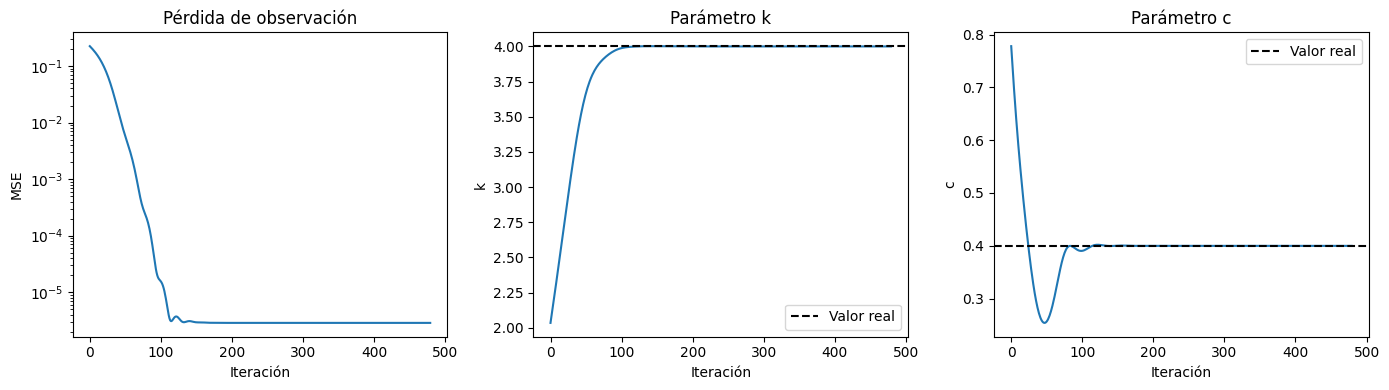

In [4]:
opt = torch.optim.Adam([eta], lr=0.04)
hist = []
for _ in range(480):
    opt.zero_grad(set_to_none=True)
    loss = perdida(); loss.backward(); opt.step()
    with torch.no_grad():
        k,c = parametros()
        hist.append([loss.item(), k.item(), c.item()])
hist = np.array(hist)
k_est,c_est = parametros()
with torch.no_grad(): pred = simular(k_est,c_est).numpy()
fig, axes = plt.subplots(1,3,figsize=(14,4))
axes[0].semilogy(hist[:,0]); axes[0].set(xlabel='Iteración',ylabel='MSE',title='Pérdida de observación')
for ax,j,real,nombre in [(axes[1],1,k_real,'k'),(axes[2],2,c_real,'c')]:
    ax.plot(hist[:,j]); ax.axhline(real,color='k',linestyle='--',label='Valor real')
    ax.set(xlabel='Iteración',ylabel=nombre,title=f'Parámetro {nombre}'); ax.legend()
plt.tight_layout(); plt.show()
print('k inferido:',k_est.item(),'| c inferido:',c_est.item())
assert abs(k_est.item()-k_real)<0.1 and abs(c_est.item()-c_real)<0.08

## 6. Datos ajustados y estados no observados

El modelo dinámico vincula posición y velocidad, de modo que las posiciones pueden restringir velocidades. Eso depende de ecuación, cobertura temporal, parámetros conocidos y condiciones iniciales; no significa que cualquier variable oculta pueda inferirse con certeza.

La curva de velocidad siguiente es una comprobación sintética contra el generador. En un experimento real necesitaríamos mediciones independientes u otra evidencia. No la tratamos como test totalmente independiente de la misma trayectoria: es validación de una variable oculta de un sistema cuyo mecanismo asumimos conocido.

RMSE posición vs generador: 0.00012308470477863582
RMSE velocidad no observada: 0.0002842383142415122


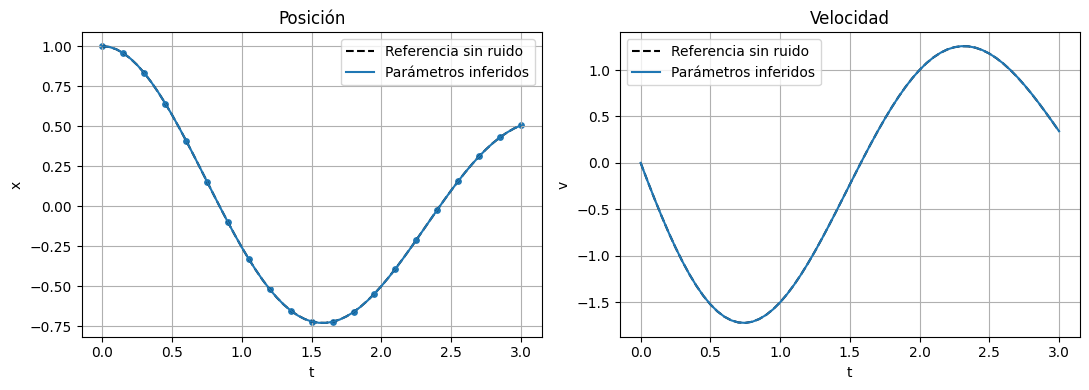

In [5]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for j,nombre in [(0,'Posición'),(1,'Velocidad')]:
    axes[j].plot(ts,sol.y[j], 'k--',label='Referencia sin ruido')
    axes[j].plot(ts,pred[:,j],label='Parámetros inferidos')
    axes[j].set(xlabel='t',ylabel=['x','v'][j],title=nombre); axes[j].legend(); axes[j].grid()
axes[0].scatter(ts[indices],y_obs_np,s=15,label='Datos')
plt.tight_layout(); plt.show()
print('RMSE posición vs generador:',np.sqrt(np.mean((pred[:,0]-sol.y[0])**2)))
print('RMSE velocidad no observada:',np.sqrt(np.mean((pred[:,1]-sol.y[1])**2)))

## 7. Derivar una solución implícita

Algunas simulaciones resuelven $F(u,\theta)=0$ en lugar de desplegar pasos explícitos. Diferenciar la identidad da

$$F_u\frac{du}{d\theta}+F_\theta=0.$$

Si $F_u$ es invertible,

$$\boxed{\frac{du}{d\theta}=-F_u^{-1}F_\theta.}$$

En código resolvemos un sistema lineal; no formamos la inversa. Para una pérdida escalar, un adjunto puede evitar calcular toda la matriz de sensibilidades: resolvemos $F_u^T\lambda=\nabla_u\mathcal L$ y usamos $d\mathcal L/d\theta=\partial_\theta\mathcal L-\lambda^TF_\theta$.

Estas fórmulas necesitan un problema localmente diferenciable y una solución suficientemente precisa. Un Jacobiano singular señala posibles ambigüedades, bifurcaciones o mala condición; no se resuelve simplemente pidiendo más gradientes a autograd.

## 8. Poisson diferenciable mediante `torch.linalg.solve`

Consideremos $-\kappa u''=\sin(\pi x)$ con $u(0)=u(1)=0$. Su discretización es $A(\kappa)u=f$, donde $A=\kappa A_0$. Por tanto, $u$ escala como $1/\kappa$ y

$$\frac{du}{d\kappa}=-\frac{u}{\kappa}.$$

PyTorch diferencia la operación de solución lineal sin que implementemos manualmente su adjunto. Comparamos el gradiente de una observación central con la identidad analítica y la solución continua $u=\sin(\pi x)/(\kappa\pi^2)$.

du_centro/dkappa: autograd= -0.15825451857279976 | fórmula= -0.1582545185728008


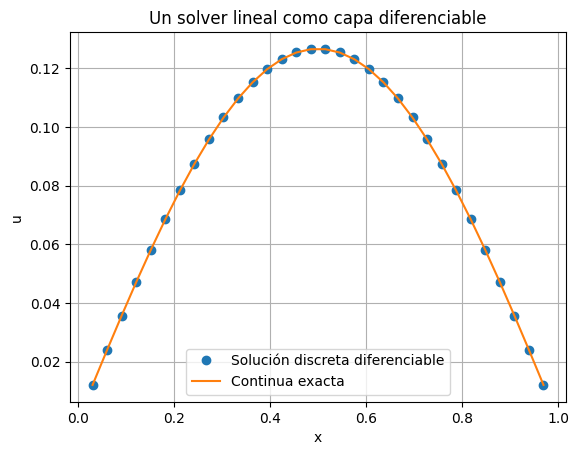

In [6]:
n_x = 32
dx = 1/(n_x+1)
x_p = torch.arange(1,n_x+1)*dx
A0 = (torch.diag(2*torch.ones(n_x))-torch.diag(torch.ones(n_x-1),1)
      -torch.diag(torch.ones(n_x-1),-1))/dx**2
f = torch.sin(torch.pi*x_p)
kappa = torch.tensor(0.8, requires_grad=True)
u = torch.linalg.solve(kappa*A0,f)
centro = n_x//2
g_imp = torch.autograd.grad(u[centro],kappa)[0]
g_formula = -u[centro].detach()/kappa.detach()
print('du_centro/dkappa: autograd=',g_imp.item(),'| fórmula=',g_formula.item())
assert torch.allclose(g_imp,g_formula,rtol=1e-10,atol=1e-12)
plt.plot(x_p.numpy(),u.detach().numpy(),'o',label='Solución discreta diferenciable')
plt.plot(x_p.numpy(),(torch.sin(torch.pi*x_p)/(kappa.detach()*torch.pi**2)).numpy(),label='Continua exacta')
plt.xlabel('x'); plt.ylabel('u'); plt.title('Un solver lineal como capa diferenciable')
plt.legend(); plt.grid(); plt.show()

## 9. Sensibilidad no equivale a identificabilidad

Una derivada distinta de cero muestra que una observación responde a un parámetro. Para varios parámetros necesitamos que sus efectos sean distinguibles. Si dos columnas de la matriz de sensibilidad son casi proporcionales, pequeñas perturbaciones de datos pueden producir grandes cambios en la estimación.

En el oscilador, observar una fracción muy corta de un periodo proporciona menos información sobre amortiguamiento que una trayectoria con varios ciclos. En Poisson, si aprendiéramos a la vez $\kappa$ y una amplitud desconocida de la fuerza, observaríamos principalmente su cociente. Regularizar puede elegir una solución, pero no crear información experimental inexistente.

El capítulo 16 estudia cómo propagar y expresar incertidumbre; aquí ajustamos valores puntuales. La dispersión de una optimización entre semillas tampoco es automáticamente una distribución posterior de parámetros.

## 10. Refinar el simulador y comprobar el gradiente

Comprobamos la trayectoria con parámetros reales usando distintos pasos, contra la referencia estricta. RK4 converge al modelo continuo en este caso suave. Al identificar parámetros, un error de simulación grande puede compensarse cambiando $k$ o $c$.

Conviene refinar después del ajuste y comprobar si cambian observaciones y derivadas. No basta verificar que una curva parezca buena a la resolución de entrenamiento. Para una simulación caótica, pequeñas diferencias pueden crecer y la ventana de validación debe elegirse con cuidado.

Errores por refinamiento: [np.float64(0.001442487141922355), np.float64(8.968084064708837e-05), np.float64(5.530966350253408e-06), np.float64(3.4344346416803617e-07)]


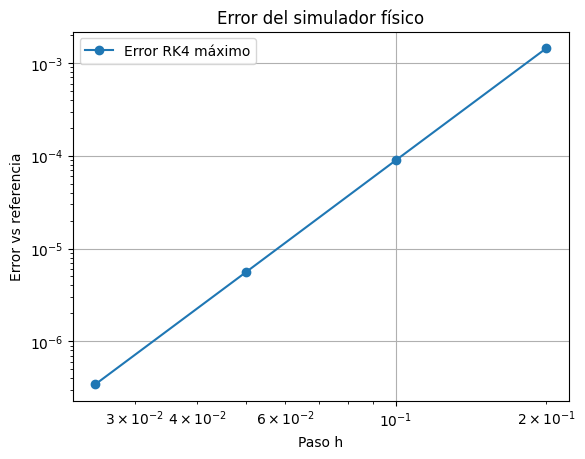

In [7]:
pasos = [15,30,60,120]
errores = []
for n in pasos:
    t_ref = np.linspace(0,tf,n+1)
    sr = solve_ivp(lambda t,z:[z[1],-k_real*z[0]-c_real*z[1]],(0,tf),[1,0],
                   t_eval=t_ref,rtol=1e-11,atol=1e-13)
    with torch.no_grad(): p = simular(torch.tensor(k_real),torch.tensor(c_real),n=n).numpy()
    errores.append(np.max(np.abs(p-sr.y.T)))
plt.loglog(tf/np.array(pasos),errores,'o-',label='Error RK4 máximo')
plt.xlabel('Paso h'); plt.ylabel('Error vs referencia'); plt.title('Error del simulador físico')
plt.legend(); plt.grid(); plt.show()
print('Errores por refinamiento:',errores)

## 11. No suavidad, eventos y operaciones discretas

Impactos, fricción seca, cambios de conectividad o decisiones de contacto introducen no suavidad. Una rama `if` puede devolver derivadas de la rama activa y omitir el efecto de cambiar de evento. Los tiempos de impacto pueden necesitar sensibilidades específicas.

Suavizar un contacto vuelve el programa derivable, pero modifica el modelo físico. Debe comprobarse la convergencia al reducir la suavización y la calidad de fuerzas o eventos, no solo la pérdida final. Operaciones como índices enteros, redondeo y selección discreta no tienen una derivada ordinaria útil respecto a esas decisiones.

También pueden aparecer gradientes inestables al desplegar muchas iteraciones. Checkpointing reduce memoria a cambio de recomputación; diferenciación implícita deriva un estado convergido bajo hipótesis; adjuntos propagan sensibilidades. La estrategia adecuada depende de estabilidad, precisión y tamaño del problema.

## 12. Diseño de un experimento de física diferenciable

Define primero qué parámetros tienen significado físico y cuáles se conocen. Después fija unidades, solver, tolerancias, operador de observación y modelo de ruido. Comprueba una solución directa y al menos una derivada antes del ajuste. Reserva observaciones o condiciones nuevas para evaluar las predicciones.

Reporta error de estados, error de parámetros cuando haya referencia, sensibilidad a ruido y discretización, y coste. Una pérdida pequeña por sí sola no distingue una buena inferencia de una compensación de errores.


| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_5_Neural_ODEs.ipynb) | [⏩](../16_UNCERTAINTY_QUANTIFICATION/16_1_UNCERTAINTY_QUANTIFICATION.ipynb) |